# Псков: городские кварталы и показатели среды

Практика 2 курса «Технологии ИИ в урбанистике». Территория: **город Псков**,
не Псковский район и не Псковская область. Версия подготовки: 23.11.2026.
Ноутбук адаптирует весь `aimclub/blocksnet/examples/pipeline.ipynb`:
кварталы → землепользование → матрица времени → здания → школы → обеспеченность,
плотности, два набора морфотипов и доступность, взвешенная площадью.

Расчёт выполнен ассистентом по прямому поручению пользователя 23.11.2026.
Для повторения запускайте ячейки сверху вниз в окружении проекта Python 3.12.
Нужны интернет для первого запуска и несколько гигабайт свободной памяти.
Повторный запуск использует сохранённые исходные слои и матрицу.

Источники: [задание](https://mvin8.github.io/ai-technologies-in-urbanism/content/practice/practice-02.html),
[исходный пример](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb),
[готовые графы Boeing](https://doi.org/10.7910/DVN/KA5HJ3),
[OpenStreetMap](https://www.openstreetmap.org/copyright).
Граф Пскова — `russia-RUS/pskov-440.graphml`, автомобильная сеть публикации 2025 года.
Данные OSM об объектах будут получены в день первого запуска. Разновременность
источников и полнота тегов ограничивают точность результатов.

**Сценарий доступности:** автомобильное движение с заданными скоростями и
условным пешим подходом к узлам. Это не оценка пешей доступности школ.
Население, площади этажей и отсутствующая вместимость школ — модельные оценки.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from enum import Enum
import hashlib
import json
import zipfile
import importlib.metadata
import shutil
import subprocess
import re
import time
from unittest.mock import patch

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import requests
import pulp
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from IPython.display import display, Markdown
from osmnx._errors import InsufficientResponseError

from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.analysis.provision import competitive_provision
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.config import service_types_config

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'examples').exists()), None)
assert ROOT is not None, 'Откройте ноутбук из папки python-package-boilerplate.'
RAW = ROOT / 'data/pskov/raw'
PROCESSED = ROOT / 'data/pskov/processed'
RESULTS = ROOT / 'results/pskov'
for folder in [RAW, PROCESSED, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)
PLACE = 'Псков, Псковская область, Россия'
ox.settings.use_cache = True
ox.settings.cache_folder = ROOT / '.cache/osmnx/pskov'
ox.settings.requests_timeout = 180
ox.settings.log_console = True
OVERPASS_URL = 'https://ovp.dresel.systems/api/interpreter'
RUN_AT = datetime.now(timezone.utc).isoformat()
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['blocksnet', 'osmnx', 'geopandas', 'numpy', 'pandas', 'scipy', 'networkx', 'pulp']}
assert VERSIONS['blocksnet'] == '1.0.0a9', VERSIONS
CBC_EXECUTABLE = next((str(p) for p in [shutil.which('cbc'), '/opt/homebrew/bin/cbc',
    '/usr/local/bin/cbc', pulp.PULP_CBC_CMD().path] if p and Path(p).is_file()), None)
assert CBC_EXECUTABLE, 'Нужен решатель CBC: на macOS установите brew install cbc.'
try:
    subprocess.run([CBC_EXECUTABLE, '-stop'], check=True, capture_output=True, timeout=15)
except (OSError, subprocess.SubprocessError) as exc:
    raise RuntimeError('CBC не запускается. На Apple Silicon нужен нативный brew install cbc.') from exc
display(pd.Series(VERSIONS, name='version').to_frame())

PROJECT_ROOT/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,version
blocksnet,1.0.0a9
osmnx,2.2.0
geopandas,1.2.0
numpy,2.2.6
pandas,2.3.3
scipy,1.18.1
networkx,3.7
pulp,2.7.0


## 0. Сохранение и повторный запуск

GeoJSON записывается в WGS84, расчёты выполняются в местной UTM (метры).
В каждом слое сохраняется `row_id`; индексы кварталов одинаковы во всех таблицах.
Исходный кэш зависит от параметров запроса и границы. Для обновления исходных
данных сначала сохраните старую версию проекта, затем удалите соответствующий
raw-файл вместе с `.meta.json` и кэш OSMnx. При обычном запуске ничего удалять не надо.

При обновлении слоя с резервного Overpass удалите после резервного копирования
его четыре кэш-файла: `<слой>.geojson`, `<слой>.meta.json`,
`<слой>.overpass.json` и `<слой>_source.meta.json`. Иначе сохранённый исходный
JSON будет использован повторно. GraphML и архив для обычного обновления OSM не удаляйте.

In [2]:
def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def file_hash(path, algorithm='sha256'):
    h = hashlib.new(algorithm)
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False, default=str))


def safe_value(value):
    if isinstance(value, Enum):
        return value.value
    if isinstance(value, (list, dict, tuple, set)):
        return json.dumps(value if not isinstance(value, set) else sorted(value), ensure_ascii=False, default=str)
    if pd.isna(value):
        return None
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    return value.item() if isinstance(value, np.generic) else value


def save_geo(frame, path):
    frame = frame.copy().to_crs(4326)
    frame['row_id'] = frame.index.astype(int)
    for column in frame.columns.difference([frame.geometry.name]):
        frame[column] = frame[column].map(safe_value)
    Path(path).write_text(frame.to_json(drop_id=True, na='null'), encoding='utf-8')


def read_geo(path):
    data = json.loads(Path(path).read_text())
    if not data['features']:
        return gpd.GeoDataFrame(geometry=[], crs=4326)
    frame = gpd.GeoDataFrame.from_features(data, crs=4326).set_index('row_id')
    frame.index = frame.index.astype(int)
    frame.index.name = None
    return frame


def cached_geo(name, parameters, loader):
    path = RAW / f'{name}.geojson'
    meta = RAW / f'{name}.meta.json'
    key = digest(parameters)
    if path.exists() and meta.exists():
        old = json.loads(meta.read_text())
        if old['key'] == key and old['sha256'] == file_hash(path):
            print(f'{name}: кэш')
            return read_geo(path)
    frame = loader().reset_index(drop=True)
    save_geo(frame, path)
    write_json(meta, dict(key=key, parameters=parameters, retrieved_at=RUN_AT, sha256=file_hash(path)))
    print(f'{name}: сохранено {len(frame)} объектов')
    return read_geo(path)


def column_or_empty(frame, name):
    return frame[name] if name in frame else pd.Series(index=frame.index, dtype='object')


def clean_geometry(frame, types):
    frame = frame[frame.geometry.notna() & ~frame.geometry.is_empty].copy()
    frame.geometry = frame.geometry.make_valid()
    return frame[frame.geom_type.isin(types)].copy().reset_index(drop=True)


def show_map(frame, column, title, categorical=False):
    fig, ax = plt.subplots(figsize=(9, 7))
    frame.plot(ax=ax, color='#dedede', edgecolor='white', linewidth=0.1)
    good = frame[column].notna()
    if not categorical:
        good &= np.isfinite(pd.to_numeric(frame[column], errors='coerce'))
    if good.any():
        frame.loc[good].plot(column=column, ax=ax, legend=True, categorical=categorical,
                             cmap='viridis' if not categorical else 'tab20')
    else:
        ax.text(0.5, 0.5, 'Нет конечных значений; см. диагностику', transform=ax.transAxes, ha='center')
    ax.set_title(title + '\nСерый — отсутствующее или бесконечное значение')
    ax.set_axis_off()
    plt.show()

## 1. Граница и нарезка кварталов

Проверка ограничивает поиск городом: название, приблизительное положение и
площадь. Это техническая проверка OSM-полигона, не подтверждение юридической
границы. Посмотрите карту: должна быть городская территория Пскова.

In [3]:
boundary_wgs = cached_geo('boundary', {'place': PLACE}, lambda: ox.geocode_to_gdf(PLACE))
assert len(boundary_wgs) == 1
assert boundary_wgs.geom_type.isin(['Polygon', 'MultiPolygon']).all()
city_name = str(column_or_empty(boundary_wgs, 'name').iloc[0]).casefold()
assert city_name in ['псков', 'pskov'], f'Проверьте найденный объект: {city_name}'
point = boundary_wgs.geometry.iloc[0].representative_point()
assert 27.5 < point.x < 29 and 57 < point.y < 58.5, 'Найден объект вне окрестностей Пскова.'
CRS = boundary_wgs.estimate_utm_crs()
boundary = boundary_wgs.to_crs(CRS)
assert 5 < boundary.area.sum() / 1e6 < 300, 'Площадь нетипична для выбранной городской территории.'
print('Территория:', PLACE, '| км²:', round(boundary.area.sum()/1e6, 2), '| CRS:', CRS)
display(boundary_wgs.drop(columns='geometry').T)
display(boundary_wgs[['geometry']].explore(tiles='OpenStreetMap'))

boundary: кэш
Территория: Псков, Псковская область, Россия | км²: 95.5 | CRS: EPSG:32635


,0
bbox_west,28.254526
bbox_south,57.744223
bbox_east,28.46357
bbox_north,57.878937
place_id,171288586
osm_type,relation
osm_id,1050399
lat,57.817392
lon,28.334346
class,boundary


In [4]:
BC_TAGS = {
    'roads': {'highway': ['construction', 'crossing', 'living_street', 'motorway', 'motorway_link',
        'motorway_junction', 'pedestrian', 'primary', 'primary_link', 'raceway', 'residential', 'road',
        'secondary', 'secondary_link', 'services', 'tertiary', 'tertiary_link', 'track', 'trunk',
        'trunk_link', 'turning_circle', 'turning_loop', 'unclassified'],
        'service': ['living_street', 'emergency_access']},
    'railways': {'railway': 'rail'},
    'water': {'riverbank': True, 'reservoir': True, 'basin': True, 'dock': True,
        'canal': True, 'pond': True, 'natural': ['water', 'bay'],
        'waterway': ['river', 'canal', 'ditch'], 'landuse': 'basin', 'water': 'lake'},
}


def fetch_features(name, tags):
    def load():
        # Compact bbox query avoids oversized URLs; OSMnx filters back to the exact polygon.
        west, south, east, north = boundary_wgs.total_bounds
        clauses = []
        for key, values in tags.items():
            if values is True:
                clauses.append(f'nwr[{json.dumps(key)}];')
            else:
                values = values if isinstance(values, list) else [values]
                pattern = '^(' + '|'.join(re.escape(value) for value in values) + ')$'
                clauses.append(f'nwr[{json.dumps(key)}~{json.dumps(pattern)}];')
        query = f'[out:json][timeout:180][bbox:{south},{west},{north},{east}];(' + ''.join(clauses) + ');out body;>;out skel qt;'
        response_path = RAW / f'{name}.overpass.json'
        response_meta = RAW / f'{name}_source.meta.json'
        request_key = digest({'endpoint': OVERPASS_URL, 'query': query})
        if (response_path.exists() and response_meta.exists()
                and json.loads(response_meta.read_text()).get('key') == request_key
                and json.loads(response_meta.read_text()).get('sha256') == file_hash(response_path)):
            payload = json.loads(response_path.read_text())
        else:
            for attempt in range(3):
                try:
                    response = requests.get(OVERPASS_URL, params={'data': query},
                        headers={'User-Agent': 'pskov-urban-ai-practice/1.0 (educational OSMnx)'}, timeout=(20, 210))
                    response.raise_for_status()
                    payload = response.json()
                    if payload.get('remark'):
                        raise RuntimeError(f'Overpass returned incomplete data: {payload["remark"]}')
                    assert 'elements' in payload
                    break
                except (requests.RequestException, ValueError, RuntimeError):
                    if attempt == 2:
                        raise
                    time.sleep(5)
            write_json(response_path, payload)
            write_json(response_meta, {'key': request_key, 'endpoint': OVERPASS_URL,
                'retrieved_at': RUN_AT, 'osm_metadata': payload.get('osm3s'), 'sha256': file_hash(response_path)})
        try:
            frame = ox.features._create_gdf([payload], boundary_wgs.geometry.union_all(), tags)
        except InsufficientResponseError as exc:
            if 'No matching features' not in str(exc):
                raise
            return gpd.GeoDataFrame(geometry=[], crs=4326)
        frame['osm_ref'] = [':'.join(map(str, idx)) for idx in frame.index]
        return frame.reset_index(drop=True)
    return cached_geo(name, {'tags': tags, 'boundary_sha256': file_hash(RAW/'boundary.geojson'),
                            'endpoint': OVERPASS_URL, 'method': 'bbox-get-polygon-filter-v1'}, load).to_crs(CRS)


roads = clean_geometry(fetch_features('roads', BC_TAGS['roads']), ['LineString', 'MultiLineString'])
railways = clean_geometry(fetch_features('railways', BC_TAGS['railways']), ['LineString', 'MultiLineString'])
water = clean_geometry(fetch_features('water', BC_TAGS['water']), ['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])
assert not roads.empty, 'Не найдены дороги для нарезки кварталов.'
display(pd.Series({'roads': len(roads), 'railways': len(railways), 'water': len(water)}, name='count'))

roads: кэш
railways: кэш
water: кэш


roads       2214
railways     252
water        125
Name: count, dtype: int64

2026-11-23 17:02:24.132 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema


2026-11-23 17:02:24.138 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema


2026-11-23 17:02:24.140 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


2026-11-23 17:02:24.143 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema


2026-11-23 17:02:24.145 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema


2026-11-23 17:02:24.149 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema


2026-11-23 17:02:24.152 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema


2026-11-23 17:02:24.152 | WARNING  | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:71 - Creating empty buildings


2026-11-23 17:02:24.199 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 933 blocks are successfully cut


Получено кварталов: 933; площадь: 91.76 км²


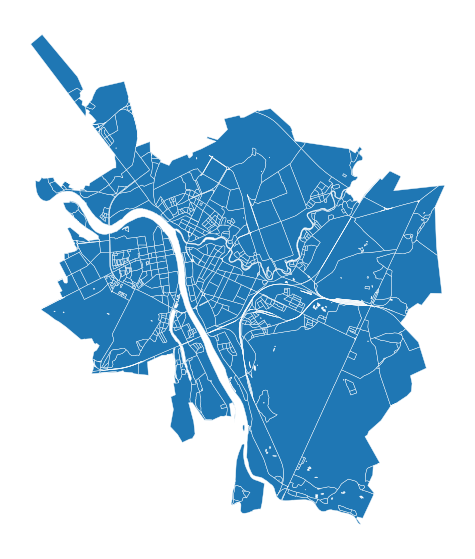

In [5]:
lines, polygons = preprocess_urban_objects(roads, railways, water)
blocks = cut_urban_blocks(boundary, lines, polygons)
blocks = clean_geometry(blocks, ['Polygon', 'MultiPolygon']).explode(index_parts=False).reset_index(drop=True)
blocks = blocks.loc[blocks.area > 0].reset_index(drop=True)[['geometry']]
assert not blocks.empty and blocks.index.is_unique
assert blocks.geometry.is_valid.all()
assert np.isclose(blocks.area.sum(), blocks.union_all().area, rtol=1e-6), 'Кварталы пересекаются.'
save_geo(blocks, PROCESSED/'blocks.geojson')
print(f'Получено кварталов: {len(blocks)}; площадь: {blocks.area.sum()/1e6:.2f} км²')
blocks.plot(figsize=(10, 7), edgecolor='white', linewidth=0.3).set_axis_off()
plt.show()

Кварталы здесь — полигоны, выделенные дорогами, железными дорогами и водой.
Они не равны кадастровым кварталам. Водные полигоны исключаются; узкие и крупные
периферийные кварталы сохраняются, чтобы не выбирать территорию по результату.

## 2. Землепользование по OSM

Правила сохранены из исходного примера. Это интерпретация тегов `landuse`,
а не официальные ПЗЗ. Неизвестные типы и территория без тега остаются неизвестными.

2026-11-23 17:02:24.403 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: greenhouse_horticulture, village_green, education, meadow, allotments, reservoir, sport, winter_sports, quarry, railway


landuse: кэш


,objects
functional_zone,
grass,377
residential,313
industrial,131
garages,95
commercial,71
retail,61
railway,36
construction,30
brownfield,28


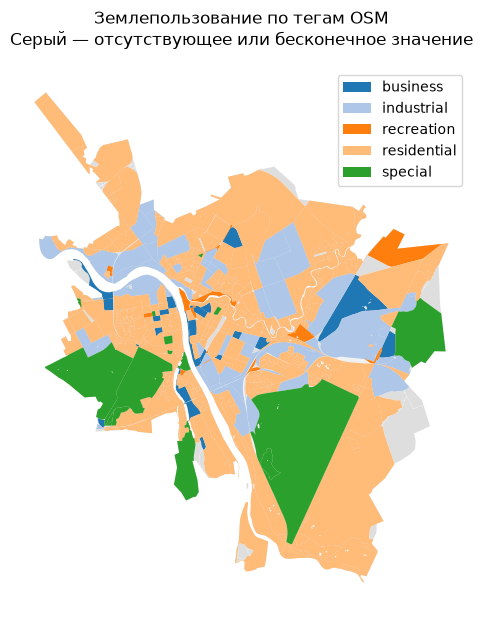

In [6]:
zones = clean_geometry(fetch_features('landuse', {'landuse': True}), ['Polygon', 'MultiPolygon'])
zones['functional_zone'] = column_or_empty(zones, 'landuse')
RULES = {
    'commercial': LandUse.BUSINESS, 'industrial': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL, 'garages': LandUse.INDUSTRIAL,
    'residential': LandUse.RESIDENTIAL, 'retail': LandUse.BUSINESS,
    'grass': LandUse.RECREATION, 'farmland': LandUse.AGRICULTURE,
    'construction': LandUse.SPECIAL, 'brownfield': LandUse.INDUSTRIAL,
    'forest': LandUse.RECREATION, 'recreation_ground': LandUse.RECREATION,
    'religious': LandUse.SPECIAL, 'flowerbed': LandUse.RECREATION,
    'military': LandUse.SPECIAL, 'landfill': LandUse.TRANSPORT,
}
if zones['functional_zone'].isin(RULES).any():
    land_use = assign_land_use(blocks, zones[['geometry', 'functional_zone']], RULES)
    land_use['land_use'] = land_use['land_use'].map(lambda x: x.value if isinstance(x, Enum) else x)
else:
    land_use = blocks.assign(land_use=None)
zones['recognized'] = zones['functional_zone'].isin(RULES)
save_geo(zones, PROCESSED/'landuse_objects.geojson')
save_geo(land_use, PROCESSED/'landuse_blocks.geojson')
display(zones['functional_zone'].value_counts().to_frame('objects'))
show_map(land_use, 'land_use', 'Землепользование по тегам OSM', categorical=True)

## 3. Готовый граф и матрица времени

Скачивается готовый архив страны (~62 МБ); извлекается только Псков.
MD5 сверяется с метаданными Dataverse, затем проверяется структура графа.
Граф соответствует городской области GHSL, а не обязательно границе муниципалитета.
Никакие рёбра или маршруты здесь не загружаются заново из OSM и не достраиваются.

In [7]:
GRAPH_URL = 'https://dataverse.harvard.edu/api/access/datafile/10962604'
GRAPH_MEMBER = 'russia-RUS/pskov-440.graphml'
ARCHIVE_MD5 = '7e180746abdbfd50343a4b794278c3c6'
archive_path = RAW/'russia-RUS_graphml.zip'
graph_path = RAW/'pskov-440.graphml'
if not archive_path.exists() or file_hash(archive_path, 'md5') != ARCHIVE_MD5:
    partial = archive_path.with_suffix('.zip.part')
    with requests.get(GRAPH_URL, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        with partial.open('wb') as stream:
            for chunk in response.iter_content(1024*1024):
                stream.write(chunk)
    assert file_hash(partial, 'md5') == ARCHIVE_MD5, 'Архив отличается от проверенной версии; остановитесь и проверьте источник.'
    partial.replace(archive_path)
    write_json(RAW/'graph_download.meta.json', {'url': GRAPH_URL, 'retrieved_at': RUN_AT, 'md5': ARCHIVE_MD5})
with zipfile.ZipFile(archive_path) as archive:
    assert GRAPH_MEMBER in archive.namelist()
    payload = archive.read(GRAPH_MEMBER)
    if not graph_path.exists() or graph_path.read_bytes() != payload:
        graph_path.write_bytes(payload)
graph = ox.load_graphml(graph_path)
assert graph.is_directed() and len(graph) > 1 and graph.number_of_edges() > 0
assert graph.graph.get('crs'), 'У графа отсутствует CRS.'
graph = ox.project_graph(graph, to_crs=CRS)
print('Узлов:', len(graph), '| рёбер:', graph.number_of_edges(), '| исходный граф:', GRAPH_MEMBER)

Узлов: 1264 | рёбер: 3140 | исходный граф: russia-RUS/pskov-440.graphml


Скорости ниже — **допущения модели**, не замеры и не ограничения скорости.
Для каждого ребра: `time_min = length_m / (speed_kmh × 1000/60)`.
Из параллельных рёбер сохраняется минимальное время; одностороннее движение
учитывается. На подход к ближайшему узлу добавляется время по прямой со скоростью
5 км/ч. Такой подход может пересекать ограды и воду; его длина сохраняется отдельно.
После проверки покрытия транспортная область ограничена кварталами не дальше
1000 м от узла основной сильно связной компоненты: между её узлами есть пути
в обе стороны. Это отдельная область транспортного расчёта, а не весь город.
Остальные кварталы остаются в анализе застройки, но транспортные показатели
у них отсутствуют. Изменение после первого запуска описано в журнале исправлений.

,snap_distance_m
count,933.000000
mean,487.382835
std,886.120348
min,1.392666
25%,54.702398
50%,108.961442
75%,389.021090
max,5363.496605


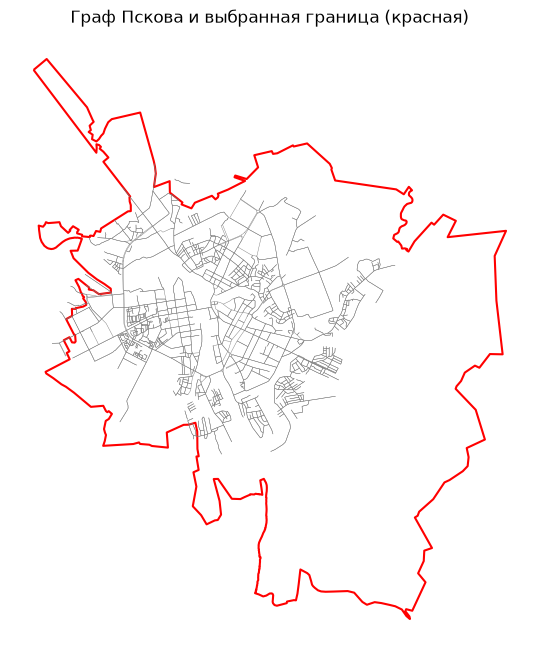

Транспортная область: 781 из 933 кварталов; исключения сохранены в graph_snaps.geojson.


In [8]:
SPEEDS_KMH = {'motorway': 90, 'motorway_link': 40, 'trunk': 70, 'trunk_link': 40,
             'primary': 50, 'primary_link': 30, 'secondary': 40, 'secondary_link': 30,
             'tertiary': 40, 'tertiary_link': 30, 'residential': 30,
             'unclassified': 30, 'service': 20, 'living_street': 10}
FALLBACK_KMH = 30
CONNECTOR_KMH = 5
MAX_SNAP_M = 1000
network = nx.DiGraph(crs=CRS.to_epsg())
network.add_nodes_from(graph.nodes(data=True))
fallback_edges = 0
for u, v, data in graph.edges(data=True):
    length = float(data['length'])
    assert np.isfinite(length) and length >= 0, 'Некорректная длина ребра.'
    highway = data.get('highway', 'unknown')
    types = highway if isinstance(highway, list) else [highway]
    speed = min(SPEEDS_KMH.get(t, FALLBACK_KMH) for t in types)
    fallback_edges += int(any(t not in SPEEDS_KMH for t in types))
    minutes = length / (speed*1000/60)
    if not network.has_edge(u, v) or minutes < network[u][v]['time_min']:
        network.add_edge(u, v, time_min=minutes)
node_ids = list(network.nodes)
node_xy = np.array([(network.nodes[n]['x'], network.nodes[n]['y']) for n in node_ids])
representatives = blocks.representative_point()
snap_m, nearest_positions = cKDTree(node_xy).query(np.column_stack([representatives.x, representatives.y]))
snaps = blocks.assign(snap_distance_m=snap_m, graph_node=[str(node_ids[i]) for i in nearest_positions])
main_strong = max(nx.strongly_connected_components(network), key=len)
node_in_main = np.array([node_ids[i] in main_strong for i in nearest_positions])
transport_mask = (snap_m <= MAX_SNAP_M) & node_in_main
transport_ids = blocks.index[transport_mask]
snaps['transport_covered'] = transport_mask
snaps['transport_exclusion'] = np.where(snap_m > MAX_SNAP_M, 'far_from_graph',
                                      np.where(~node_in_main, 'outside_main_strong_component', 'included'))
save_geo(snaps, PROCESSED/'graph_snaps.geojson')
display(snaps[['snap_distance_m']].describe())
fig, ax = plt.subplots(figsize=(10, 8))
boundary.boundary.plot(ax=ax, color='red', linewidth=1.5)
graph_edges = ox.graph_to_gdfs(graph, nodes=False)
graph_edges.plot(ax=ax, color='#777777', linewidth=0.3)
ax.set_title('Граф Пскова и выбранная граница (красная)')
ax.set_axis_off()
plt.show()
assert len(transport_ids) > 1, 'Нет достаточной транспортной области.'
print(f'Транспортная область: {len(transport_ids)} из {len(blocks)} кварталов; исключения сохранены в graph_snaps.geojson.')

Матрица содержит кратчайшее время из квартала `i` в квартал `j`, в минутах.
Используется алгоритм Дейкстры SciPy на готовом графе: это замена технической
реализации матрицы из примера, сохраняющая несвязные компоненты и минимальные
веса параллельных рёбер. Матрица ограничена явно сохранённой транспортной областью.
Недостижимые пары имели бы `inf`, диагональ — 0. Вне области время неизвестно.
Представительная точка находится внутри квартала; это не обязательно центр населения.
Привязка по прямой — только первый и последний участки, не замена сетевого маршрута.

In [9]:
matrix_key = digest({'graph': file_hash(graph_path), 'blocks': file_hash(PROCESSED/'blocks.geojson'),
                     'speeds': SPEEDS_KMH, 'fallback': FALLBACK_KMH, 'connector': CONNECTOR_KMH,
                     'algorithm': 'directed-minparallel-mainstrong-snap1000-v2',
                     'transport_ids': transport_ids.tolist(), 'versions': VERSIONS})
matrix_path = PROCESSED/'accessibility_matrix.npz'
matrix_meta = PROCESSED/'accessibility_matrix.meta.json'
use_matrix_cache = (matrix_path.exists() and matrix_meta.exists()
    and json.loads(matrix_meta.read_text())['key'] == matrix_key
    and json.loads(matrix_meta.read_text()).get('sha256') == file_hash(matrix_path))
if use_matrix_cache:
    with np.load(matrix_path, allow_pickle=False) as saved:
        matrix = saved['minutes']
        assert np.array_equal(saved['block_ids'], transport_ids.to_numpy())
    print('Матрица: кэш')
else:
    n = len(transport_ids)
    assert n <= 10000, f'{n} кварталов: проверьте нарезку и доступную память перед расчётом n².'
    node_index = {node: i for i, node in enumerate(node_ids)}
    edges = list(network.edges(data=True))
    sparse = csr_matrix(([d['time_min'] for u, v, d in edges],
                        ([node_index[u] for u, v, d in edges], [node_index[v] for u, v, d in edges])),
                        shape=(len(node_ids), len(node_ids)))
    matrix = np.full((n, n), np.inf, dtype=np.float32)
    # Chunking bounds working memory; every origin remains in the final matrix.
    for start in range(0, n, 64):
        stop = min(start+64, n)
        distances = dijkstra(sparse, directed=True, indices=nearest_positions[transport_mask][start:stop])
        matrix[start:stop] = distances[:, nearest_positions[transport_mask]]
    connector_min = snap_m[transport_mask]/(CONNECTOR_KMH*1000/60)
    matrix += connector_min[:, None].astype(np.float32) + connector_min[None, :].astype(np.float32)
    np.fill_diagonal(matrix, 0)
    np.savez_compressed(matrix_path, minutes=matrix, block_ids=transport_ids.to_numpy())
    write_json(matrix_meta, {'key': matrix_key, 'computed_at': RUN_AT, 'units': 'minutes', 'sha256': file_hash(matrix_path)})
assert matrix.shape == (len(transport_ids), len(transport_ids))
assert not np.isnan(matrix).any() and (matrix >= 0).all() and (matrix.diagonal() == 0).all()
acc_mx = pd.DataFrame(matrix, index=transport_ids, columns=transport_ids)
acc_mx.to_csv(RESULTS/'accessibility_matrix.csv', index_label='block_id')
off_diag = ~np.eye(len(transport_ids), dtype=bool)
unreachable_fraction = float((~np.isfinite(matrix) & off_diag).sum()/max(1, off_diag.sum()))
print(f'Недостижимые направленные пары: {unreachable_fraction:.1%}; слабых компонент графа: {nx.number_weakly_connected_components(network)}')
display(acc_mx.iloc[:5, :5])

Матрица: кэш
Недостижимые направленные пары: 0.0%; слабых компонент графа: 8


,2,3,6,7,8
2,0.000000,7.284508,12.428666,11.821965,13.845970
3,7.284508,0.000000,12.927090,12.320389,14.344395
6,11.563657,12.941313,0.000000,1.256111,3.280116
7,11.037368,12.415024,1.336523,0.000000,2.753827
8,12.980961,14.358618,3.280116,2.673415,0.000000


## 4. Здания и оценка населения

Жилые типы и параметры повторяют пример: 30 м² жилой площади на человека,
90% площади этажей жилого здания отнесены к жилой. Неизвестная этажность заменяется
одним этажом. `building=yes` не подтверждает жилую функцию, поэтому оценка населения
может быть занижена. Считаются целые здания, чьи представительные точки внутри
городской границы; на краю кварталов это создаёт погрешность распределения площадей.

In [10]:
buildings_raw = fetch_features('buildings', {'building': True})
buildings_input = clean_geometry(buildings_raw, ['Polygon', 'MultiPolygon'])
buildings_input = buildings_input.loc[buildings_input.representative_point().intersects(boundary.union_all())].reset_index(drop=True)
assert not buildings_input.empty, 'Нет полигональных зданий для расчёта.'
# One physical footprint may have two OSM ways with corner-address variants.
# Remove only exact geometry duplicates with the same building type and floor tag.
duplicate_keys = pd.DataFrame({
    'geometry_wkb': buildings_input.geometry.to_wkb(),
    'building_type': column_or_empty(buildings_input, 'building').fillna(''),
    'floor_tag': column_or_empty(buildings_input, 'building:levels').fillna(''),
})
duplicate_mask = duplicate_keys.duplicated(keep='first')
duplicate_buildings = buildings_input.loc[duplicate_mask].copy()
duplicate_buildings['exclusion_reason'] = 'Identical footprint, building type and floor tag; first source object retained'
save_geo(duplicate_buildings, PROCESSED/'buildings_exact_duplicates.geojson')
print(f'Повторных представлений зданий исключено: {duplicate_mask.sum()}')
buildings_input = buildings_input.loc[~duplicate_mask].reset_index(drop=True)
buildings_input['is_living'] = column_or_empty(buildings_input, 'building').isin(
    ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory'])
floors = pd.to_numeric(column_or_empty(buildings_input, 'building:levels'), errors='coerce')
floors = floors.where(np.isfinite(floors) & (floors > 0))
buildings_input['number_of_floors'] = floors
building_flags = pd.DataFrame({
    'osm_ref': column_or_empty(buildings_input, 'osm_ref'),
    'floors_imputed': floors.isna(),
    'residential_type_unknown': column_or_empty(buildings_input, 'building').isin(['yes', 'building']),
    'population_is_model': True,
}, index=buildings_input.index)
buildings = impute_buildings(buildings_input[['geometry', 'is_living', 'number_of_floors']], default_living_demand=30)
buildings['population'] = buildings['population'].fillna(0)
building_fields = ['footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'population']
assert np.isfinite(buildings[building_fields]).all().all() and (buildings[building_fields] >= 0).all().all()
save_geo(buildings.join(building_flags), PROCESSED/'buildings.geojson')
display(buildings.head())
print(f'Этажность восстановлена у {building_flags.floors_imputed.mean():.1%} зданий.')

buildings: кэш


2026-11-23 17:02:26.063 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None


2026-11-23 17:02:26.063 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-11-23 17:02:26.064 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-11-23 17:02:26.064 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-11-23 17:02:26.064 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


Повторных представлений зданий исключено: 2


,geometry,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population
0,"POLYGON ((579528 6408976.344, 579537.64 640900...",False,1.0,1397.506215,1397.506215,0.000000,1397.506215,0.0
1,"POLYGON ((578769.668 6408800.904, 578771.832 6...",False,2.0,1928.854278,3857.708556,0.000000,3857.708556,0.0
2,"POLYGON ((578091.34 6408787.675, 578093.867 64...",False,3.0,3432.131901,10296.395702,0.000000,10296.395702,0.0
3,"MULTIPOLYGON (((577689.903 6409806.028, 577691...",True,5.0,2059.987119,10299.935593,9269.942034,1029.993559,308.0
4,"MULTIPOLYGON (((578295.737 6408346.079, 578298...",False,1.0,1023.489662,1023.489662,0.000000,1023.489662,0.0


Этажность восстановлена у 82.3% зданий.


2026-11-23 17:02:26.477 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-11-23 17:02:26.480 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


buildings: в кварталах 15320, вне кварталов 1


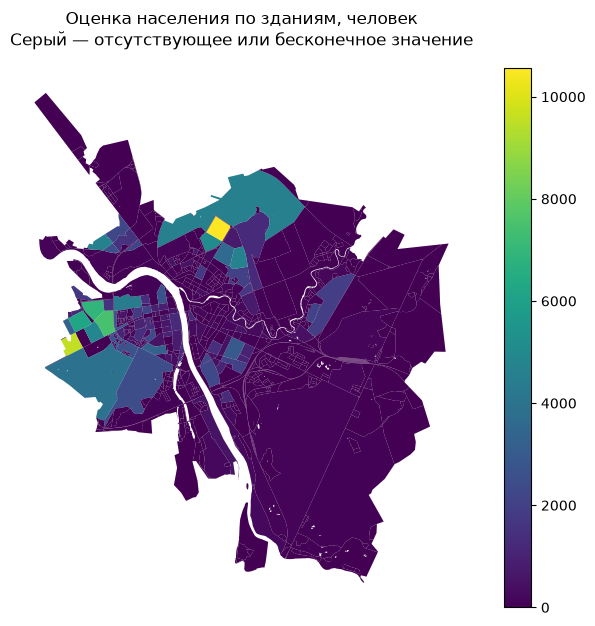

In [11]:
def aggregate_checked(objects, fields, label):
    # Numeric source identifiers/flags are deliberately not aggregated.
    aggregated, excess = aggregate_objects(blocks, objects[['geometry', *fields]].copy())
    points = objects[['geometry']].copy()
    points.geometry = points.representative_point()
    joins = points.sjoin(blocks[['geometry']], how='inner', predicate='intersects')
    assert not joins.index.duplicated().any(), f'{label}: объект попал в два квартала; проверьте границы.'
    for field in fields:
        expected = objects.loc[joins.index, field].sum()
        assert np.isclose(aggregated[field].sum(), expected), f'{label}: нарушено сохранение суммы {field}.'
    aggregated[fields] = aggregated[fields].fillna(0)
    unassigned = objects.loc[~objects.index.isin(joins.index)]
    save_geo(unassigned, PROCESSED/f'{label}_unassigned.geojson')
    print(f'{label}: в кварталах {len(joins)}, вне кварталов {len(unassigned)}')
    return aggregated, unassigned


buildings_blocks, buildings_unassigned = aggregate_checked(buildings, building_fields, 'buildings')
save_geo(buildings_blocks, PROCESSED/'buildings_blocks.geojson')
show_map(buildings_blocks, 'population', 'Оценка населения по зданиям, человек')

## 5. Школы и вместимость

Вместимость из OSM используется, если это неотрицательное целое число.
Иначе `impute_services` подставляет минимальную единицу школы из конфигурации
BlocksNet (в установленной версии — 250 мест). Это не проверенная фактическая
вместимость. Точка внутри полигона школы с совпадающим либо отсутствующим
названием считается повторным представлением; список удалённых дублей сохраняется.
Совпадения с разными названиями требуют проверки и сохраняются в диагностике.

2026-11-23 17:02:26.710 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-11-23 17:02:26.711 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


schools: кэш
schools: в кварталах 41, вне кварталов 0


Восстановлена вместимость 40 из 41 школ; конфликтов названий: 0.


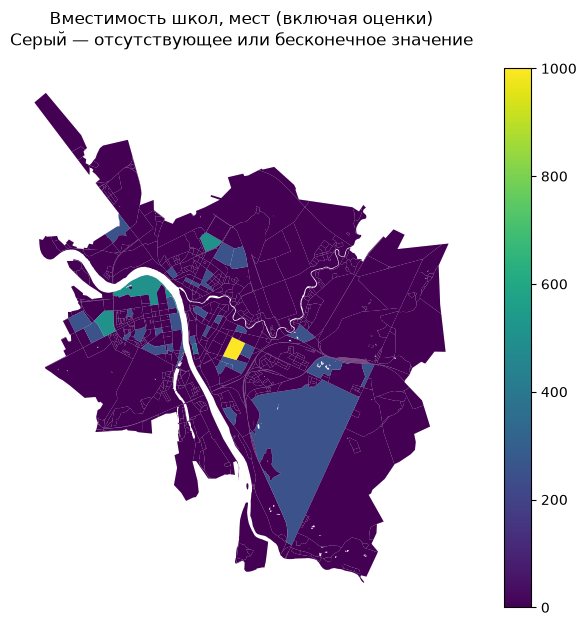

In [12]:
schools_input = clean_geometry(fetch_features('schools', {'amenity': 'school'}), ['Point', 'Polygon', 'MultiPolygon'])
schools_input = schools_input.loc[schools_input.representative_point().intersects(boundary.union_all())].reset_index(drop=True)
assert not schools_input.empty, 'OSM не вернул школы; нельзя интерпретировать это как отсутствие школ в городе.'
# Decisions after source review; raw objects are preserved unchanged.
SCHOOL_EXCLUSIONS = {
    'node:1192521260': 'Название: центр внешкольной работы; не общеобразовательная школа',
    'node:1218125444': 'Название и sport=soccer: футбольная школа',
    'node:12728147801': 'Название: кибершкола; дополнительное образование',
    'way:293275088': 'Безымянная территория полностью включает именованное здание школы №12 way:94572301; один объект учтён один раз',
}
excluded_schools = schools_input.loc[schools_input.osm_ref.isin(SCHOOL_EXCLUSIONS)].copy()
excluded_schools['exclusion_reason'] = excluded_schools.osm_ref.map(SCHOOL_EXCLUSIONS)
save_geo(excluded_schools, PROCESSED/'schools_review_excluded.geojson')
schools_input = schools_input.loc[~schools_input.osm_ref.isin(SCHOOL_EXCLUSIONS)].reset_index(drop=True)
names = (column_or_empty(schools_input, 'name').fillna('').str.casefold()
         .str.replace(r'\([^)]*\)', '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip())
polygons_school = schools_input.loc[schools_input.geom_type.isin(['Polygon', 'MultiPolygon'])]
duplicate_ids, conflicts = [], []
for idx, row in schools_input.loc[schools_input.geom_type == 'Point'].iterrows():
    containing = polygons_school.loc[polygons_school.intersects(row.geometry)]
    for poly_id in containing.index:
        if not names.loc[idx] or not names.loc[poly_id] or names.loc[idx] == names.loc[poly_id]:
            duplicate_ids.append(idx)
            break
        conflicts.append({'point_id': int(idx), 'polygon_id': int(poly_id), 'point_name': names.loc[idx], 'polygon_name': names.loc[poly_id]})
save_geo(schools_input.loc[sorted(set(duplicate_ids))], PROCESSED/'schools_duplicate_points.geojson')
pd.DataFrame(conflicts, columns=['point_id', 'polygon_id', 'point_name', 'polygon_name']).to_csv(RESULTS/'school_name_conflicts.csv', index=False)
schools_input = schools_input.drop(index=duplicate_ids).reset_index(drop=True)
capacity = pd.to_numeric(column_or_empty(schools_input, 'capacity'), errors='coerce')
capacity = capacity.where(np.isfinite(capacity) & (capacity >= 0) & (capacity % 1 == 0))
schools_input['capacity'] = capacity
school_flags = pd.DataFrame({'osm_ref': column_or_empty(schools_input, 'osm_ref'),
                             'name': column_or_empty(schools_input, 'name'),
                             'capacity_imputed': capacity.isna()}, index=schools_input.index)
schools = impute_services(schools_input[['geometry', 'capacity']], 'school')
save_geo(schools.join(school_flags), PROCESSED/'schools.geojson')
schools_blocks, schools_unassigned = aggregate_checked(schools, ['capacity'], 'schools')
save_geo(schools_blocks, PROCESSED/'schools_blocks.geojson')
print(f'Восстановлена вместимость {school_flags.capacity_imputed.sum()} из {len(schools)} школ; конфликтов названий: {len(conflicts)}.')
show_map(schools_blocks, 'capacity', 'Вместимость школ, мест (включая оценки)')

## 6. Подготовленные данные

Все исходные слои находятся в `data/pskov/raw`, расчётные — в
`data/pskov/processed`. Объекты, не попавшие ни в один квартал, сохранены отдельно.
Таблица ниже позволяет увидеть потери при агрегировании до интерпретации модели.

In [13]:
audit = pd.DataFrame([
    {'layer': 'buildings', 'input': len(buildings), 'unassigned': len(buildings_unassigned),
     'total': buildings.population.sum(), 'assigned_total': buildings_blocks.population.sum(), 'units': 'estimated persons'},
    {'layer': 'schools', 'input': len(schools), 'unassigned': len(schools_unassigned),
     'total': schools.capacity.sum(), 'assigned_total': schools_blocks.capacity.sum(), 'units': 'places incl. imputed'},
])
audit.to_csv(RESULTS/'aggregation_audit.csv', index=False)
display(audit)

,layer,input,unassigned,total,assigned_total,units
0,buildings,15321,1,194541.0,194541.0,estimated persons
1,schools,41,0,10365.0,10365.0,places incl. imputed


## 7.1. Конкурентная обеспеченность школами

Спрос — `ceil(население × demand / 1000)`, параметр `demand` берётся из
конфигурации школы. `provision_strong` — доля спроса, обеспеченного в пределах
порога времени, `provision_weak` — доля обеспеченного спроса с учётом разрешённых
дополнительных зон. Здесь `max_depth=1`, как по умолчанию в примере, поэтому
расширенных зон нет. Внутриквартальное самообеспечение включено и принимает время 0.
Порог конфигурации (15 минут) применён к нашему **автомобильному сценарию**;
по этим результатам нельзя утверждать соблюдение норм пешей доступности школ.
Модель распределяет целочисленные места с учётом спроса, вместимости и времени;
это не фактическое закрепление учеников за школами. Для Apple Silicon подключаем
нативный CBC вместо несовместимого бинарного файла PuLP. Статус решения проверяется.

2026-11-23 17:02:26.889 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-11-23 17:02:26.890 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-11-23 17:02:26.893 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-11-23 17:02:26.896 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-11-23 17:02:27.203 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Мест на 1000 жителей: 120 | порог времени, мин: 15


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
2,0,0,0,0,0,0,0,0,NaN,NaN
3,1150,0,0,1150,0,0,0,0,1.0,1.0
6,2,0,2,0,0,0,0,0,0.0,0.0
7,0,0,0,0,0,0,0,0,NaN,NaN
8,4,0,4,0,0,0,0,0,0.0,0.0


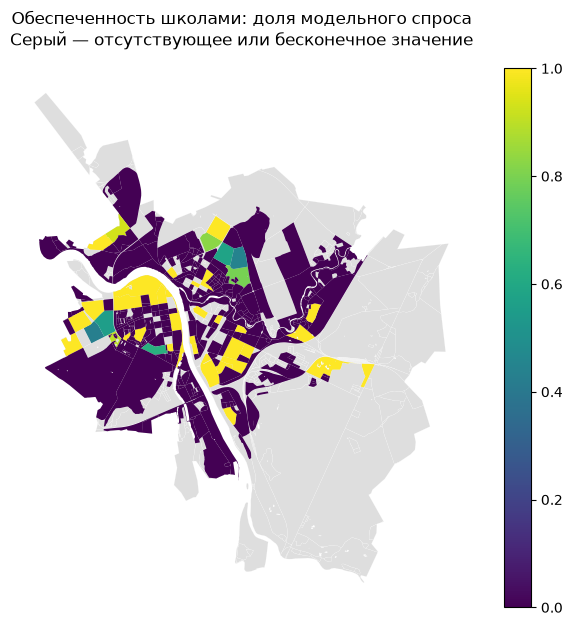

In [14]:
school_config = service_types_config['school']
school_demand = int(school_config['demand'])
school_accessibility = int(school_config['accessibility'])
provision_input = buildings_blocks[['population']].join(schools_blocks[['capacity']]).fillna(0).loc[transport_ids]


class CheckedCBC(pulp.COIN_CMD):
    def actualSolve(self, problem, **kwargs):
        result = super().actualSolve(problem, **kwargs)
        if problem.status != pulp.LpStatusOptimal:
            raise RuntimeError(f'Решение обеспеченности не оптимально: {pulp.LpStatus[problem.status]}')
        return result


def native_cbc(**kwargs):
    return CheckedCBC(path=CBC_EXECUTABLE, **kwargs)


with patch('blocksnet.analysis.provision.competitive.core.PULP_CBC_CMD', new=native_cbc):
    prov_df, links_df = competitive_provision(provision_input, acc_mx,
        accessibility=school_accessibility, demand=school_demand, self_supply=True, max_depth=1)
prov_df.to_csv(RESULTS/'school_provision.csv', index_label='block_id')
links_df.to_csv(RESULTS/'school_provision_links.csv')
assert ((prov_df['provision_strong'].dropna() >= 0) & (prov_df['provision_strong'].dropna() <= 1)).all()
assert (prov_df[['demand_left', 'capacity_left']] >= -1e-6).all().all()
assert np.allclose(prov_df.demand, prov_df.demand_within + prov_df.demand_without + prov_df.demand_left)
print('Мест на 1000 жителей:', school_demand, '| порог времени, мин:', school_accessibility)
display(prov_df.head())
show_map(blocks.join(prov_df), 'provision_strong', 'Обеспеченность школами: доля модельного спроса')

## 7.2. Плотности и морфотипы

Обозначения: S — площадь квартала, F — площадь пятен зданий, A — площадь этажей,
R — жилая площадь, N — нежилая, все площади в м².

| Поле | Формула / смысл | Единица |
|---|---|---|
| fsi | A/S, интенсивность застройки | м²/м² |
| gsi | F/S, покрытие зданиями, BlocksNet ограничивает 0…1 | доля |
| mxi | R/A, доля жилой площади | доля |
| l | A/F, средняя этажность по пятнам, минимум 1 | этажи |
| osr | (S−F)/A, открытая площадь на площадь этажей | м²/м² |
| share_living | R/F, жилая площадь на площадь пятен | м²/м² |
| share_non_living | N/F, нежилая площадь на площадь пятен | м²/м² |

Последние два показателя **не доли от 0 до 1**, несмотря на название.
При нулевом знаменателе оставляем пропуск. Суммарные пятна могут перекрываться
в исходных OSM-данных; диагностика сохраняется, отрицательный OSR не исправляется
на красивое значение. Морфотипы — классификации модели, не официальные типы районов.

,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
count,9.330000e+02,933.000000,933.000000,933.000000,933.000000,933.000000,933.000000,571.000000,571.000000,571.000000,571.000000,571.000000
mean,9.835408e+04,6378.540958,14009.041270,6302.041736,7706.999533,0.204386,0.078865,0.302149,2.046176,31.808843,1.032639,1.013537
std,4.293559e+05,18631.784224,39465.252416,24880.814433,22183.993508,0.404920,0.092369,0.349901,1.883324,199.163484,1.875221,0.569305
min,8.620921e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.140660,0.000000,0.100000
25%,3.582399e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.832330,0.000000,0.719865
50%,1.300711e+04,994.360377,1057.976288,0.000000,613.588707,0.057347,0.053518,0.091832,1.000000,7.035106,0.117864,1.000000
75%,4.044363e+04,3777.977400,7326.293965,1053.473349,3220.553112,0.157142,0.129441,0.638726,2.409989,12.451905,0.900000,1.009954
max,8.310868e+06,226516.276742,387363.613245,317026.142480,254823.066888,3.971858,0.517420,0.900000,15.422720,3805.579946,13.880448,4.332843


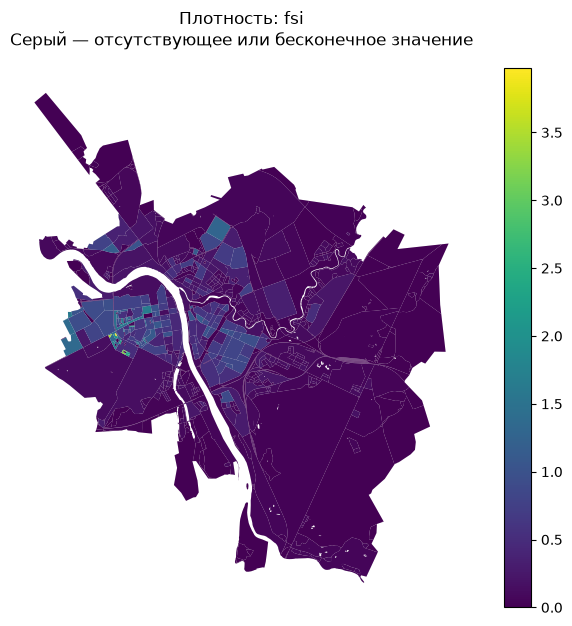

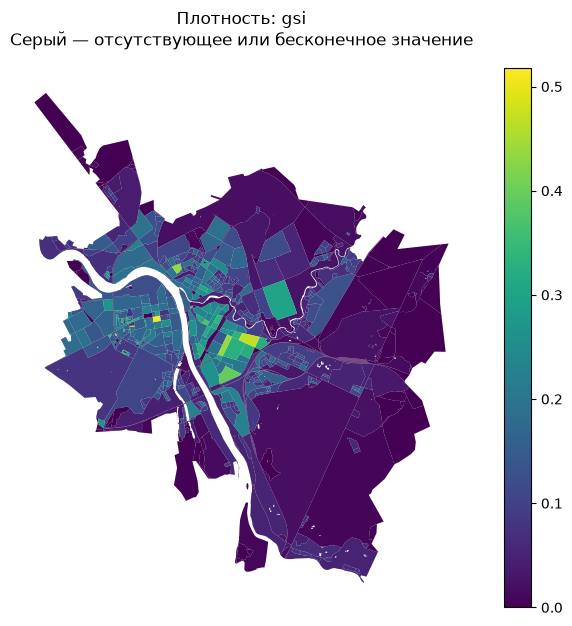

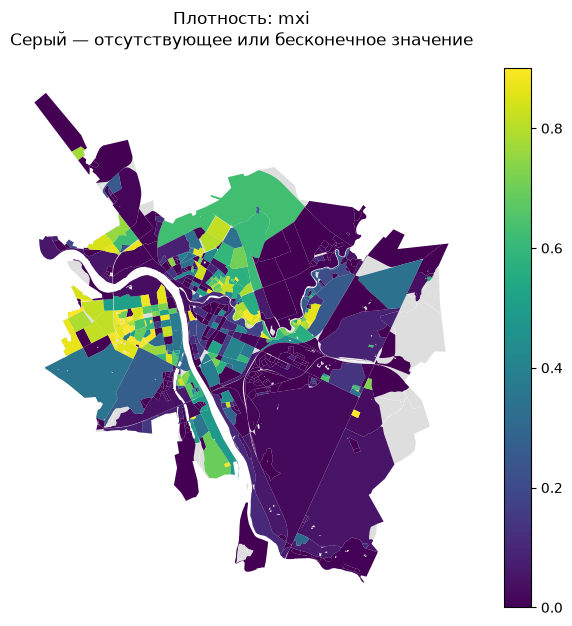

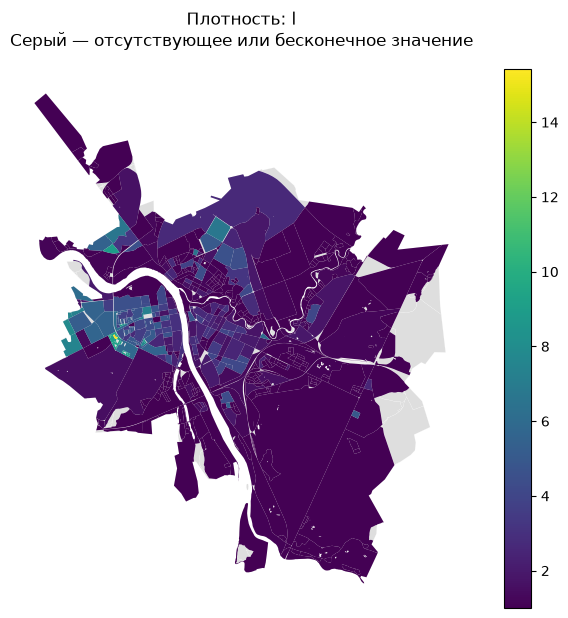

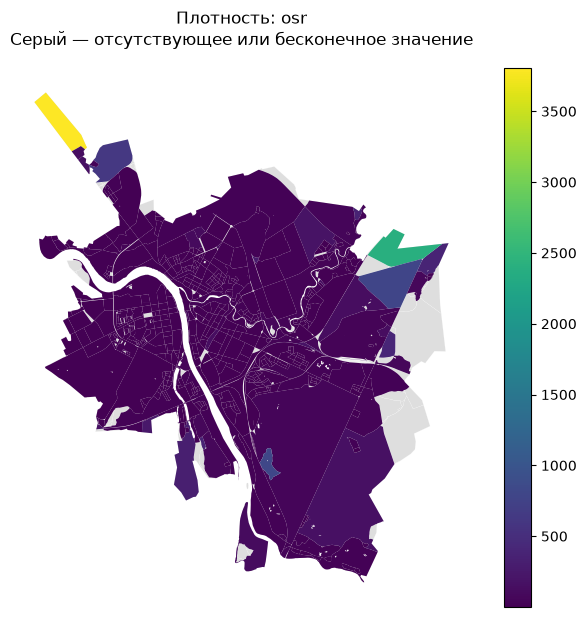

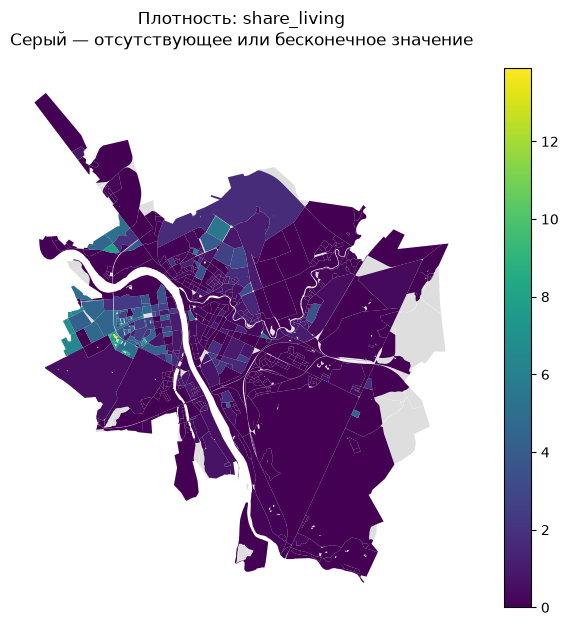

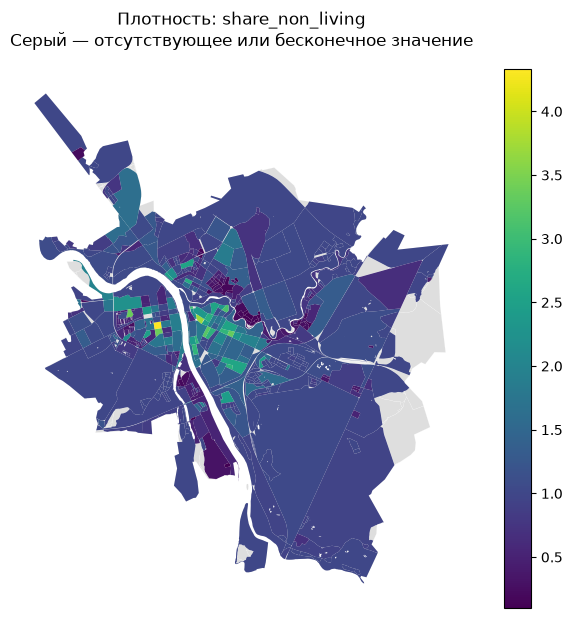

In [15]:
buildings_blocks['site_area'] = blocks.area
density_df = calculate_density_indicators(buildings_blocks).replace([np.inf, -np.inf], np.nan)
density_df.to_csv(RESULTS/'density.csv', index_label='block_id')
density_warnings = pd.DataFrame({
    'footprint_exceeds_site': buildings_blocks.footprint_area > buildings_blocks.site_area,
    'no_building_footprint': buildings_blocks.footprint_area == 0,
}, index=blocks.index)
density_warnings.to_csv(RESULTS/'density_warnings.csv', index_label='block_id')
display(density_df.describe())
for metric in ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']:
    show_map(blocks.join(density_df), metric, f'Плотность: {metric}')

**Spacematrix** группирует кварталы по стандартизированным FSI, L и MXI
методом KMeans. В примере 11 кластеров; если пригодных кварталов или уникальных
сочетаний меньше, число уменьшается и записывается в манифест. Названия типов
получаются из медиан параметров кластера. Результат показывает сходство застройки
внутри этого набора данных; номера кластеров не являются оценками качества.

**«Стрелка»** использует фиксированные пороги: L < 4 — малоэтажная застройка,
4 ≤ L < 9 — среднеэтажная, L ≥ 9 — многоэтажная. Внутри групп BlocksNet
различает типы по FSI и MXI. Это категориальный показатель без единиц измерения.
Например, слово «советский» в метке модели не подтверждает дату постройки домов.
Кварталам без пригодных данных о застройке морфотип не назначается.

Число кластеров Spacematrix: 11 (исходный пример: 11); кварталов с классификацией: 571


PROJECT_ROOT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
PROJECT_ROOT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
PROJECT_ROOT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.087705,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,5.000000,0.819752,0.867609,mid-rise,low-density,residential,mid-rise low-density residential
2,1.000000,0.098700,0.770671,low-rise,low-density,residential,low-rise low-density residential
3,9.000000,2.081616,0.900000,high-mid-rise,high-density,residential,high-mid-rise high-density residential
4,2.714518,0.633353,0.101439,low-rise,low-density,non-residential,low-rise low-density non-residential
5,3.595724,0.621541,0.600472,mid-rise,low-density,residential,mid-rise low-density residential
6,1.000000,0.099180,0.349710,low-rise,low-density,mixed-use,low-rise low-density mixed-use
7,1.212550,0.263065,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
8,7.556949,1.345427,0.872217,high-mid-rise,None,residential,high-mid-rise residential


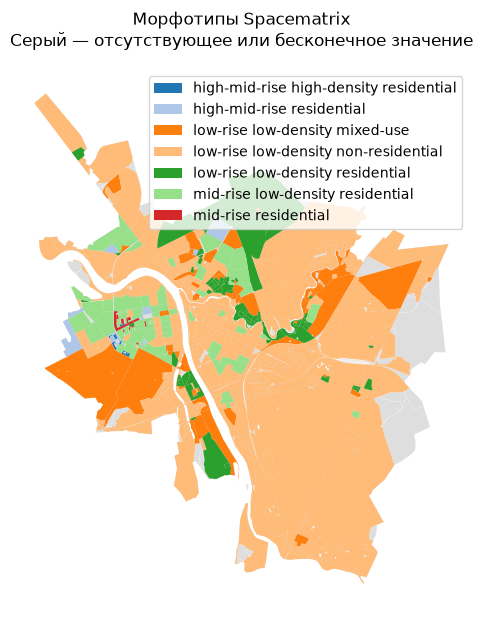

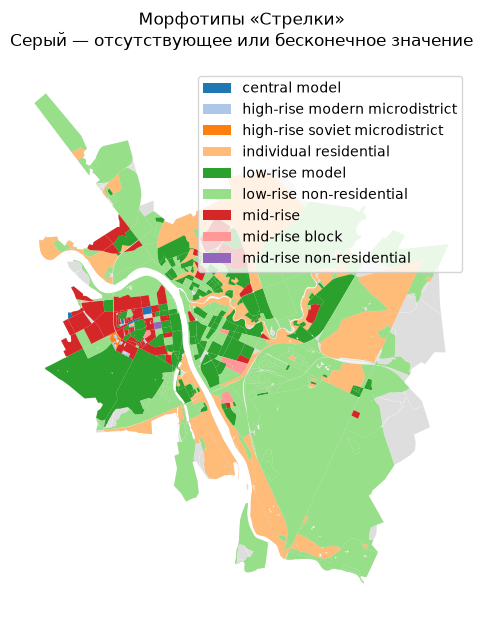

In [16]:
morph_input = density_df[['fsi', 'l', 'mxi']].dropna()
morph_input = morph_input.loc[morph_input.fsi > 0]
assert not morph_input.empty, 'Нет кварталов с параметрами для морфотипов.'
n_clusters = min(11, len(morph_input), len(morph_input.drop_duplicates()))
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(morph_input, n_clusters=n_clusters, random_state=42)
strelka_df = get_strelka_morphotypes(morph_input)
spacematrix_df.to_csv(RESULTS/'spacematrix.csv', index_label='block_id')
spacematrix_clusters.to_csv(RESULTS/'spacematrix_clusters.csv', index_label='cluster_id')
strelka_df.to_csv(RESULTS/'strelka.csv', index_label='block_id')
print('Число кластеров Spacematrix:', n_clusters, '(исходный пример: 11); кварталов с классификацией:', len(morph_input))
display(spacematrix_clusters)
show_map(blocks.join(spacematrix_df), 'morphotype', 'Морфотипы Spacematrix', categorical=True)
show_map(blocks.join(strelka_df), 'morphotype', 'Морфотипы «Стрелки»', categorical=True)

## 7.3. Доступность, взвешенная площадью

Исходный показатель: `Σⱼ(timeᵢⱼ × areaⱼ) / Σⱼ(areaⱼ)`, минуты.
Чем меньше, тем быстрее доступ к территории других кварталов в этом сценарии.
Если есть недостижимый квартал, исходный показатель равен бесконечности.
Дополнительно считаются доля достижимой площади и среднее **только по достижимой
площади**. Второе нельзя сравнивать без первого: малая изолированная сеть может
дать обманчиво низкое среднее. Все кварталы и недостижимые пары остаются в матрице.

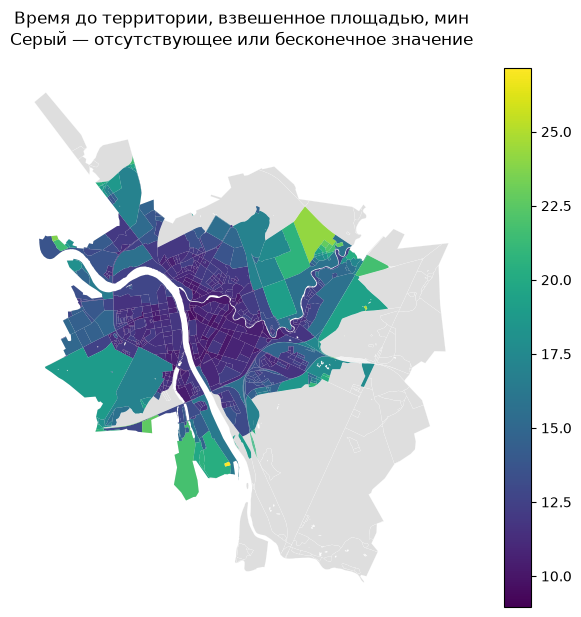

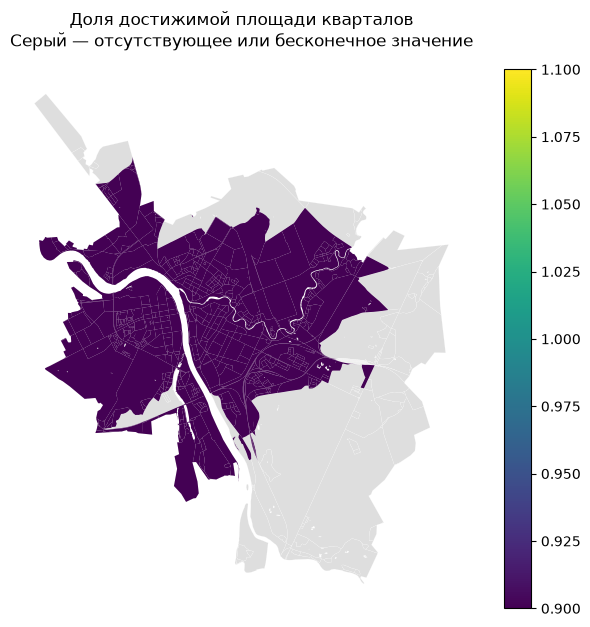

,area_accessibility,reachable_area_share,reachable_only_time_min
count,781.000000,781.0,781.000000
mean,13.035259,1.0,13.035259
std,3.240113,0.0,3.240113
min,8.956147,1.0,8.956147
25%,11.046123,1.0,11.046123
50%,11.837754,1.0,11.837754
75%,14.107935,1.0,14.107935
max,27.148498,1.0,27.148498


In [17]:
area_acc = area_accessibility(acc_mx, buildings_blocks.loc[transport_ids, ['site_area']])
reachable = np.isfinite(matrix)
areas = blocks.loc[transport_ids].area.to_numpy()
reachable_area = (reachable * areas[None, :]).sum(axis=1)
area_acc['reachable_area_share'] = reachable_area / areas.sum()
area_acc['reachable_only_time_min'] = (np.where(reachable, matrix, 0) * areas[None, :]).sum(axis=1) / reachable_area
area_acc['has_unreachable_destinations'] = (~reachable).any(axis=1)
area_acc.to_csv(RESULTS/'area_accessibility.csv', index_label='block_id')
show_map(blocks.join(area_acc), 'area_accessibility', 'Время до территории, взвешенное площадью, мин')
show_map(blocks.join(area_acc), 'reachable_area_share', 'Доля достижимой площади кварталов')
display(area_acc.describe())

## 8. Итоговые файлы, словарь и ограничения

Итоговый GeoJSON соединяет все показатели с геометрией кварталов.
В CSV бесконечность сохраняется как `inf`; в GeoJSON она записывается как `null`,
а отдельный флаг `has_unreachable_destinations` сохраняет причину.
Исходные таблицы каждого метода сохраняются полностью, включая служебные поля.
После выполнения подготовлен `dashboard.html`; команда сборки из сохранённых
результатов: `python build_dashboard.py`.

In [18]:
metrics = land_use.copy()
metrics = metrics.join(buildings_blocks.drop(columns='geometry').add_prefix('building_'))
metrics = metrics.join(schools_blocks.drop(columns='geometry').add_prefix('school_'))
metrics = metrics.join(prov_df.add_prefix('provision_'))
metrics = metrics.join(density_df.add_prefix('density_'))
metrics = metrics.join(spacematrix_df[['morphotype', 'cluster']].add_prefix('spacematrix_'))
metrics = metrics.join(strelka_df[['morphotype']].add_prefix('strelka_'))
metrics = metrics.join(area_acc).join(snaps[['snap_distance_m', 'transport_covered', 'transport_exclusion']]).join(density_warnings)
assert metrics.index.equals(blocks.index) and len(metrics) == len(blocks)
save_geo(metrics, RESULTS/'blocks_metrics.geojson')
metrics.drop(columns='geometry').to_csv(RESULTS/'blocks_metrics.csv', index_label='block_id')

catalog = [
    ('land_use', '2', 'OSM landuse mapped by rules', 'category', 'landuse_blocks.geojson'),
    ('population', '4', 'floor(living_area / 30); at least 1 in residential building', 'estimated persons', 'buildings_blocks.geojson'),
    ('capacity', '5', 'OSM capacity or BlocksNet imputation', 'places', 'schools_blocks.geojson'),
    ('provision_strong', '7.1', 'demand_within / demand', 'fraction', 'school_provision.csv'),
    ('provision_weak', '7.1', '(demand_within + demand_without) / demand', 'fraction', 'school_provision.csv'),
    ('fsi', '7.2', 'A/S', 'm2/m2', 'density.csv'),
    ('gsi', '7.2', 'clip(F/S, 0, 1)', 'fraction', 'density.csv'),
    ('mxi', '7.2', 'clip(R/A, 0, 1)', 'fraction', 'density.csv'),
    ('l', '7.2', 'max(A/F, 1)', 'floors', 'density.csv'),
    ('osr', '7.2', '(S-F)/A', 'm2/m2', 'density.csv'),
    ('share_living', '7.2', 'R/F', 'm2/m2', 'density.csv'),
    ('share_non_living', '7.2', 'N/F', 'm2/m2', 'density.csv'),
    ('spacematrix_morphotype', '7.2', 'KMeans and BlocksNet interpretation', 'category', 'spacematrix.csv'),
    ('strelka_morphotype', '7.2', 'BlocksNet thresholds', 'category', 'strelka.csv'),
    ('area_accessibility', '7.3', 'sum(t_ij*S_j)/sum(S_j)', 'minutes', 'area_accessibility.csv'),
]
coverage = pd.DataFrame(catalog, columns=['metric', 'notebook_section', 'definition', 'unit', 'file'])
coverage['dashboard_status'] = 'pending: create after notebook execution'
coverage.to_csv(RESULTS/'metric_coverage.csv', index=False)
write_json(RESULTS/'metric_dictionary.json', coverage.to_dict('records'))

In [19]:
weighted_provision = float(prov_df['demand_within'].sum()/prov_df['demand'].sum()) if prov_df['demand'].sum() else None
manifest = {
    'city': PLACE, 'run_at': RUN_AT, 'versions': VERSIONS, 'crs': CRS.to_string(),
    'graph_url': GRAPH_URL, 'graph_member': GRAPH_MEMBER, 'graph_sha256': file_hash(graph_path),
    'graph_mode': 'drive', 'graph_publication_year': 2025,
    'transport_scope': {'rule': 'nearest full-graph node in largest strong component and snap <= 1000 m',
                        'blocks': len(transport_ids), 'block_ids': transport_ids.tolist(),
                        'area_km2': float(blocks.loc[transport_ids].area.sum()/1e6),
                        'population_estimate': float(buildings_blocks.loc[transport_ids].population.sum()),
                        'capacity': float(schools_blocks.loc[transport_ids].capacity.sum())},
    'cbc_executable': CBC_EXECUTABLE,
    'sources': [json.loads(p.read_text()) for p in sorted(RAW.glob('*.meta.json'))],
    'assumptions': {'speed_kmh': SPEEDS_KMH, 'fallback_kmh': FALLBACK_KMH, 'connector_kmh': CONNECTOR_KMH,
                    'max_snap_m': MAX_SNAP_M, 'living_demand_m2': 30, 'missing_floors': 1,
                    'school_config': school_config, 'self_supply': True, 'max_depth': 1,
                    'school_review_exclusions': SCHOOL_EXCLUSIONS,
                    'spacematrix_clusters': n_clusters, 'random_state': 42},
    'diagnostics': {'blocks': len(blocks), 'buildings': len(buildings), 'schools': len(schools),
                    'exact_duplicate_buildings_removed': len(duplicate_buildings),
                    'unassigned_buildings': len(buildings_unassigned), 'unassigned_schools': len(schools_unassigned),
                    'school_name_conflicts': len(conflicts), 'unreachable_pairs_share': unreachable_fraction,
                    'max_snap_m': float(snap_m.max()), 'speed_fallback_edges': fallback_edges,
                    'footprint_exceeds_site': int(density_warnings.footprint_exceeds_site.sum()),
                    'imputed_floors_share': float(building_flags.floors_imputed.mean()),
                    'imputed_school_capacity_share': float(school_flags.capacity_imputed.mean())},
    'outputs': {str(p.relative_to(ROOT)): file_hash(p) for p in sorted(RESULTS.iterdir())
                if p.is_file() and p.name in {
                    'accessibility_matrix.csv', 'aggregation_audit.csv', 'area_accessibility.csv',
                    'blocks_metrics.csv', 'blocks_metrics.geojson', 'density.csv', 'density_warnings.csv',
                    'metric_coverage.csv', 'metric_dictionary.json', 'school_name_conflicts.csv',
                    'school_provision.csv', 'school_provision_links.csv', 'spacematrix.csv',
                    'spacematrix_clusters.csv', 'strelka.csv'}},
    'status': 'computed; requires student interpretation and map review',
}
write_json(RESULTS/'manifest.json', manifest)
summary = f'''# Псков: результаты запуска

Дата (UTC): {RUN_AT}. Кварталов: {len(blocks)}.
Модельная численность в кварталах: {buildings_blocks.population.sum():,.0f} человек.
Вместимость школ в кварталах, включая восстановленную: {schools_blocks.capacity.sum():,.0f} мест.
Транспортная область: {len(transport_ids)} из {len(blocks)} кварталов.
Доля модельного спроса, обеспеченного в пределах порога внутри транспортной области: {weighted_provision if weighted_provision is not None else 'спрос отсутствует'}.
Недостижимые направленные пары: {unreachable_fraction:.2%}.

Это результат автомобильного сценария с условным пешим подходом. Численность и
восстановленные вместимости не являются официальной статистикой. Исходный граф
и текущие слои OSM разновременны. Требуется проверить карту привязок, школы с
восстановленной вместимостью, конфликты названий и объекты вне кварталов.
Показатели описывают модель; они не доказывают причины городских различий.
'''
(RESULTS/'summary.md').write_text(summary, encoding='utf-8')
display(Markdown(summary))
display(metrics[['geometry', 'land_use', 'building_population', 'school_capacity',
                 'provision_provision_strong', 'density_fsi', 'spacematrix_morphotype',
                 'strelka_morphotype', 'reachable_area_share']].explore(
    column='density_fsi', cmap='viridis', tiles='OpenStreetMap', tooltip=True))
print('Сохранено:', RESULTS)

# Псков: результаты запуска

Дата (UTC): 2026-11-23T14:02:23.190516+00:00. Кварталов: 933.
Модельная численность в кварталах: 194,541 человек.
Вместимость школ в кварталах, включая восстановленную: 10,365 мест.
Транспортная область: 781 из 933 кварталов.
Доля модельного спроса, обеспеченного в пределах порога внутри транспортной области: 0.44430290784503207.
Недостижимые направленные пары: 0.00%.

Это результат автомобильного сценария с условным пешим подходом. Численность и
восстановленные вместимости не являются официальной статистикой. Исходный граф
и текущие слои OSM разновременны. Требуется проверить карту привязок, школы с
восстановленной вместимостью, конфликты названий и объекты вне кварталов.
Показатели описывают модель; они не доказывают причины городских различий.


Сохранено: PROJECT_ROOT/results/pskov


## 9. Самопроверка и следующий шаг

Сохраните ноутбук с результатами (`Cmd+S`). Проверьте карту города и графа,
`aggregation_audit.csv`, `school_name_conflicts.csv`, `density_warnings.csv`.
При ошибке сохраните полный текст ошибки и номер ячейки для исправления кода.
Не продолжайте после неуспешного обязательного `assert`.

Самопроверка: выберите два квартала и объясните, почему высокий FSI не обязательно
означает высокую обеспеченность школами. Разберите площадь застройки, население,
школьные места, порог времени и конкуренцию за вместимость. Найдите один квартал
с восстановленной этажностью/вместимостью и объясните, как это влияет на вывод.

Следующий этап выполнен: `build_dashboard.py` читает
сохранённые GeoJSON/CSV/manifest и собирает `dashboard.html` со всеми показателями
из `metric_coverage.csv`. Полное сопоставление — в `dashboard_metric_coverage.csv`.
Студенту остаётся проверить интерпретацию и
оформляет собственный GitHub-репозиторий с ноутбуком, кодом, выводами и промптами.
История этого проекта содержит подготовку кода в Codex; её нельзя выдавать за
самостоятельно выполненную сессию OpenCode. При требовании преподавателя работы
именно в OpenCode используйте сохранённый план и промпт для проверки/развития кода там.

### Мой ответ для самопроверки

Заполните после выполнения расчётов своими словами:

- Я сравнила кварталы с `row_id` … и … . Их FSI составляет … и … .
- Обеспеченность различается, потому что модель учитывает … .
- В исходных данных восстановлен параметр …; при его изменении вывод может … .
- Перед практической рекомендацией городу я бы проверила … .